In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, pearsonr, probplot

In [2]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
df.info()
df.columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

Part 1 — Best-seller por categoría

In [4]:
crosstab = pd.crosstab(df["category"], df["isBestSeller"])

crosstab.head()

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


In [5]:
crosstab["best_seller_proportion"] = crosstab[True] / (crosstab[True] + crosstab[False])

best_seller_by_category = crosstab.sort_values(
    "best_seller_proportion", 
    ascending=False
)

best_seller_by_category.head(10)

isBestSeller,False,True,best_seller_proportion
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339
"Billiard, Snooker & Pool",241,8,0.032129
Pet Supplies,9152,285,0.030200
Home Brewing & Wine Making,239,7,0.028455
Wind Instruments,243,7,0.028000


Las categorías con mayor proporción de productos best-seller son las primeras de la tabla. 
Esto no significa necesariamente que tengan más productos en total, sino que dentro de esa categoría hay una mayor proporción de productos marcados como best-seller.

In [6]:
contingency_table = pd.crosstab(df["category"], df["isBestSeller"])

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

chi2, p_value

(np.float64(36540.20270061387), np.float64(0.0))

El test Chi-square permite comprobar si existe una relación entre la categoría del producto y si es best-seller o no.

Si el p-value es menor que 0.05, podemos decir que la distribución de best-sellers no es independiente de la categoría.

In [7]:
n = contingency_table.sum().sum()
min_dim = min(contingency_table.shape) - 1

cramers_v = np.sqrt(chi2 / (n * min_dim))

cramers_v

np.float64(0.1222829439760564)

Cramér's V mide la fuerza de asociación entre la categoría y el estado de best-seller.

Aunque el Chi-square indique relación estadística, Cramér's V nos ayuda a saber si esa relación es fuerte o débil.

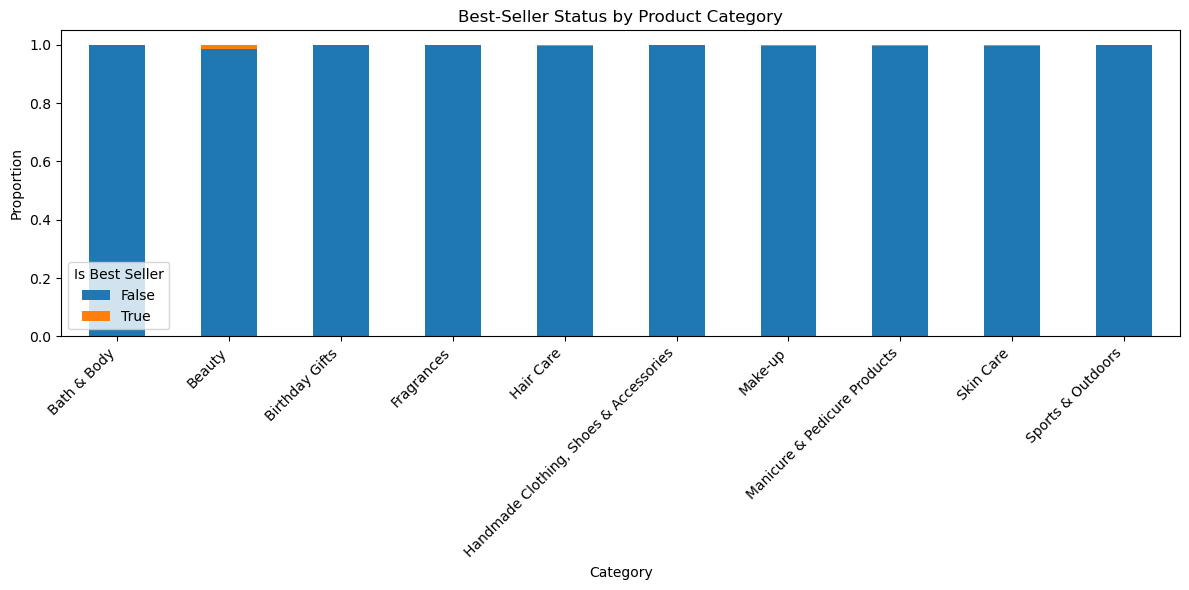

In [8]:
top_10_categories = df["category"].value_counts().head(10).index

df_top_10 = df[df["category"].isin(top_10_categories)]

stacked_data = pd.crosstab(
    df_top_10["category"], 
    df_top_10["isBestSeller"], 
    normalize="index"
)

stacked_data.plot(kind="bar", stacked=True, figsize=(12, 6))

plt.title("Best-Seller Status by Product Category")
plt.xlabel("Category")
plt.ylabel("Proportion")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Is Best Seller")
plt.tight_layout()
plt.show()

Part 2 — Prices and ratings

In [9]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_no_outliers = df[
    (df["price"] >= lower_bound) & 
    (df["price"] <= upper_bound)
]

df_no_outliers.shape

(2115963, 9)

Se eliminaron los outliers de la variable price usando el método IQR. 
A partir de este punto, el análisis se realiza con el dataframe sin precios extremos.

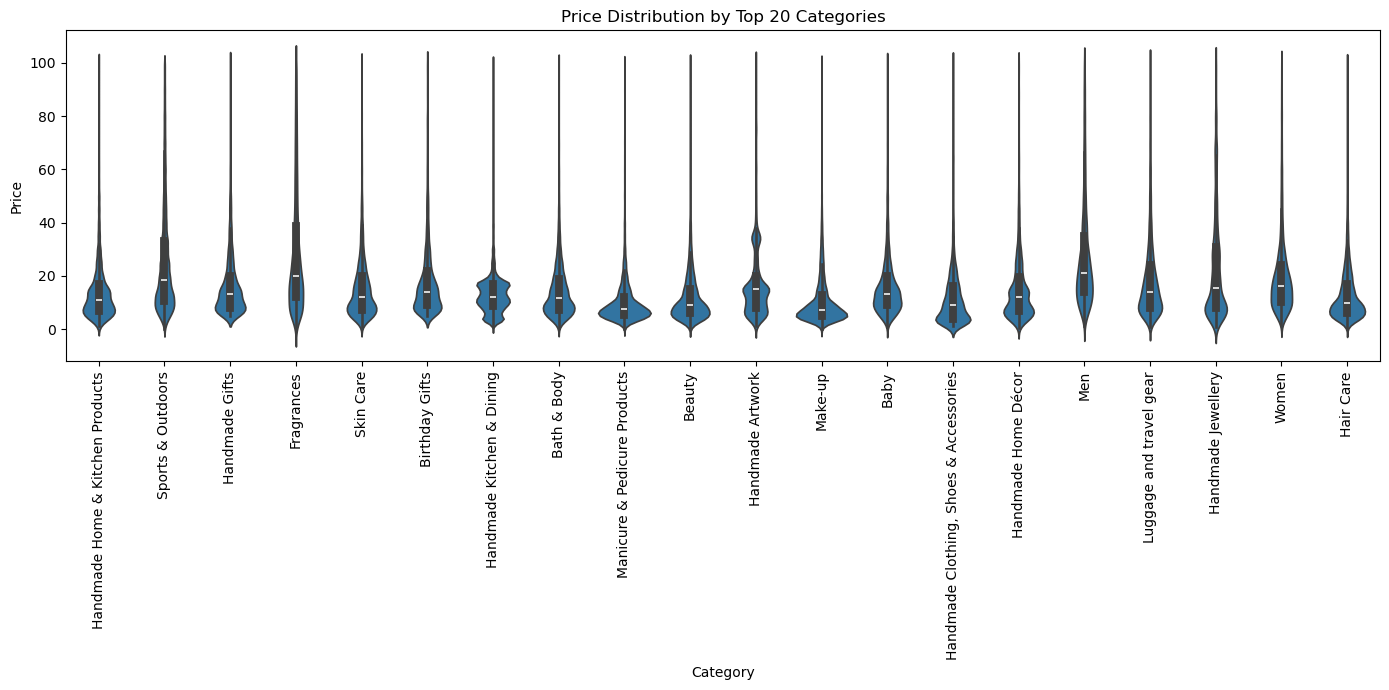

In [10]:
top_20_categories = df_no_outliers["category"].value_counts().head(20).index

df_top_20 = df_no_outliers[df_no_outliers["category"].isin(top_20_categories)]

plt.figure(figsize=(14, 7))
sns.violinplot(data=df_top_20, x="category", y="price")

plt.title("Price Distribution by Top 20 Categories")
plt.xlabel("Category")
plt.ylabel("Price")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [11]:
median_price_by_category = df_no_outliers.groupby("category")["price"].median().sort_values(ascending=False)

median_price_by_category.head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

La categoría con mayor mediana de precio es la primera de la tabla. 
La mediana es útil porque representa el precio central sin verse tan afectada por valores extremos.

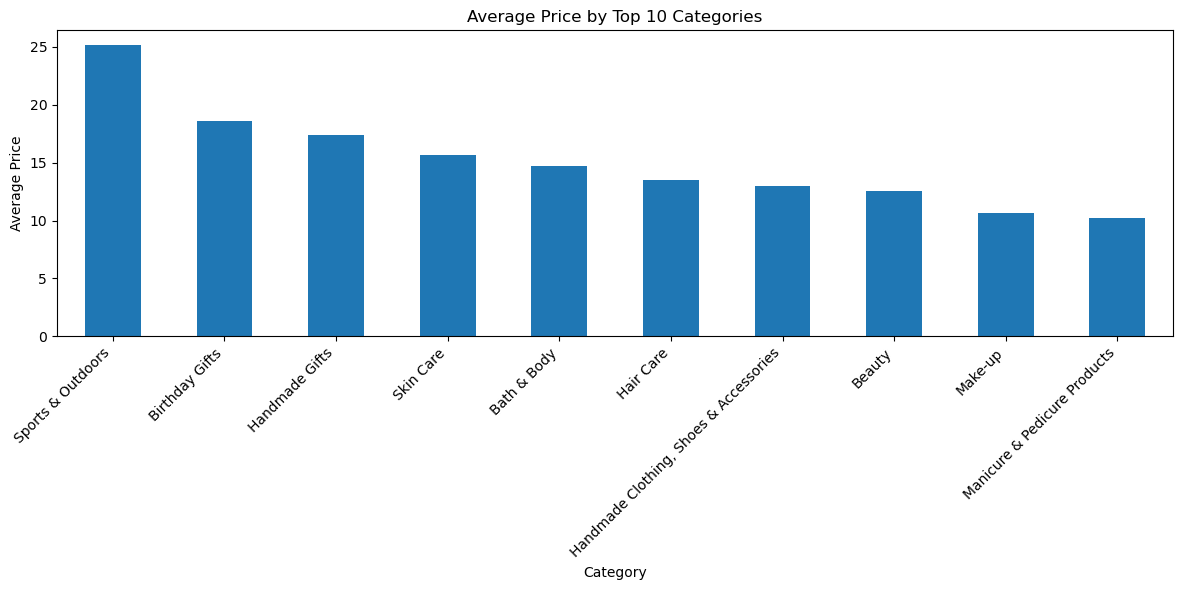

In [12]:
top_10_categories = df_no_outliers["category"].value_counts().head(10).index

avg_price_top_10 = (
    df_no_outliers[df_no_outliers["category"].isin(top_10_categories)]
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))
avg_price_top_10.plot(kind="bar")

plt.title("Average Price by Top 10 Categories")
plt.xlabel("Category")
plt.ylabel("Average Price")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [13]:
avg_price_by_category = df_no_outliers.groupby("category")["price"].mean().sort_values(ascending=False)

avg_price_by_category.head(10)

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

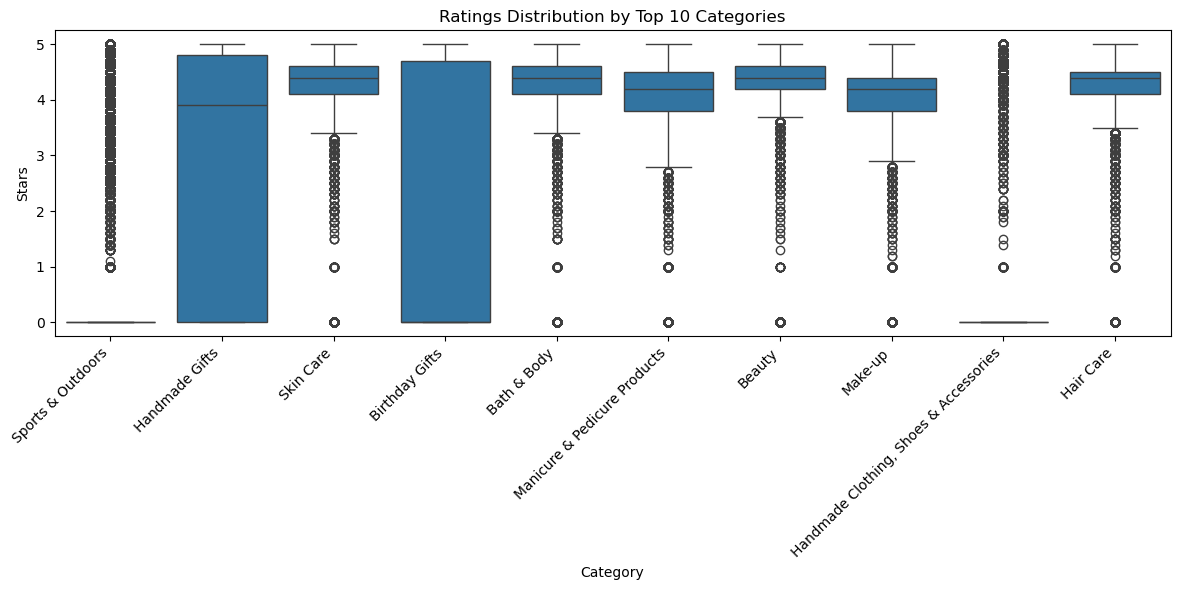

In [14]:
top_10_categories = df_no_outliers["category"].value_counts().head(10).index

df_top_10 = df_no_outliers[df_no_outliers["category"].isin(top_10_categories)]

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top_10, x="category", y="stars")

plt.title("Ratings Distribution by Top 10 Categories")
plt.xlabel("Category")
plt.ylabel("Stars")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [15]:
median_rating_by_category = df_no_outliers.groupby("category")["stars"].median().sort_values(ascending=False)

median_rating_by_category.head(10)

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Hobbies                         4.6
Beer, Wine & Spirits            4.6
Laptop Accessories              4.6
Cables & Accessories            4.5
CPUs                            4.5
Name: stars, dtype: float64

Part 3 — Price vs ratings

In [16]:
correlation = df_no_outliers["price"].corr(df_no_outliers["stars"])

correlation

np.float64(-0.0776729987818137)

La correlación mide si existe relación lineal entre el precio y la valoración del producto.

Si el valor está cerca de 0, significa que no hay una relación lineal fuerte.
Si está cerca de 1, la relación es positiva.
Si está cerca de -1, la relación es negativa.

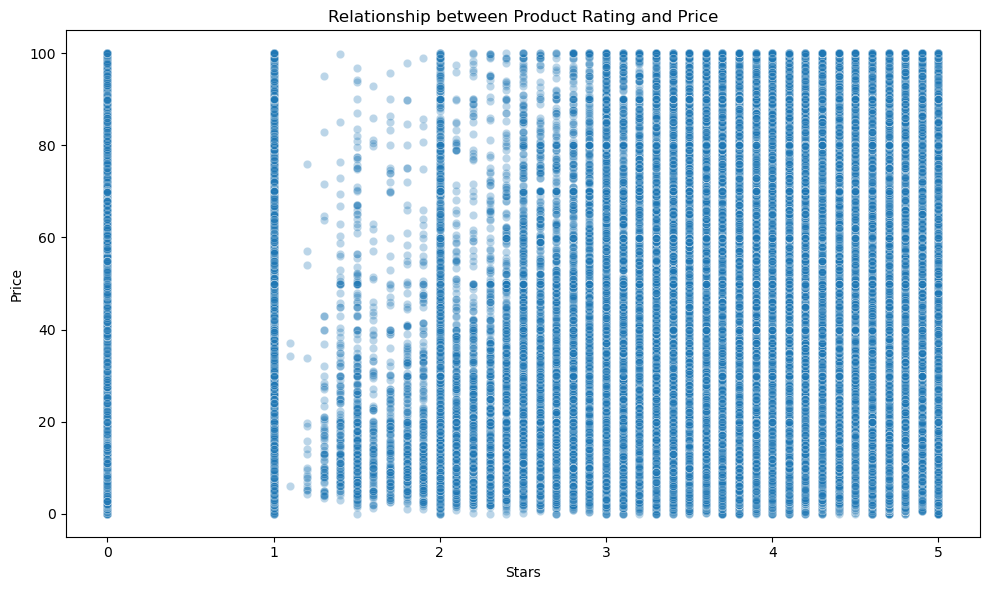

In [17]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_no_outliers, x="stars", y="price", alpha=0.3)

plt.title("Relationship between Product Rating and Price")
plt.xlabel("Stars")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

En el scatter plot podemos observar si los productos con mejores ratings tienden a tener precios más altos o más bajos. 
Si los puntos están muy dispersos, significa que no existe un patrón claro entre price y stars.

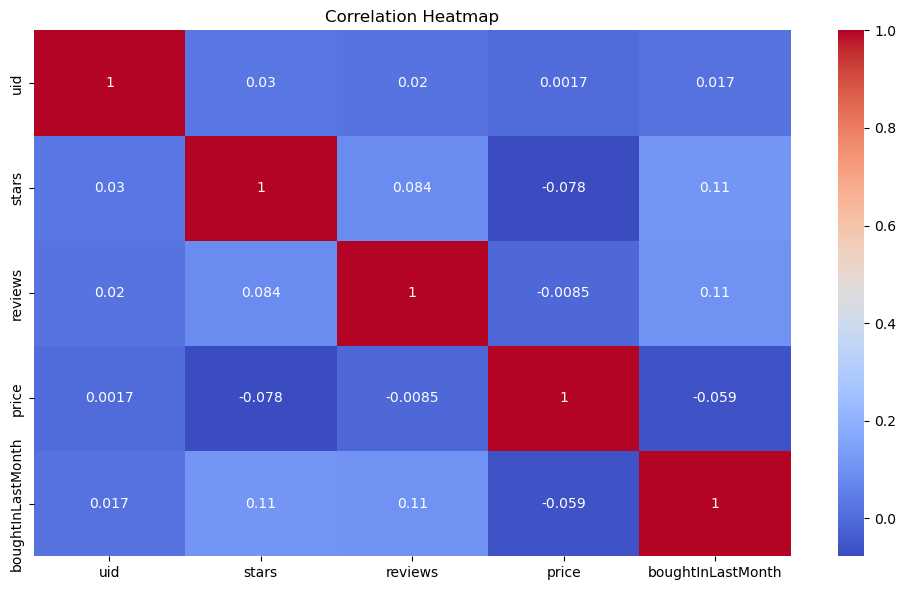

In [18]:
numeric_df = df_no_outliers.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(10, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

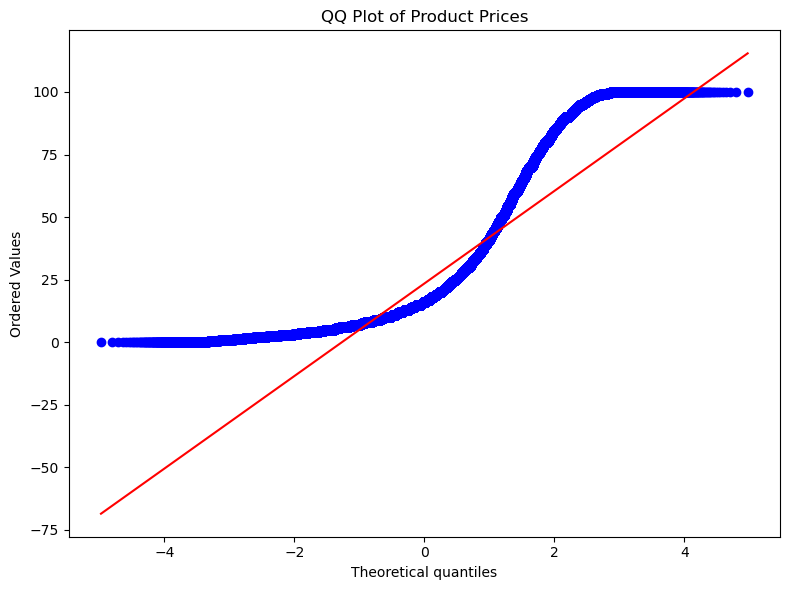

In [19]:
plt.figure(figsize=(8, 6))
probplot(df_no_outliers["price"], dist="norm", plot=plt)

plt.title("QQ Plot of Product Prices")
plt.tight_layout()
plt.show()

El QQ plot permite comprobar si la variable price sigue una distribución normal.

Si los puntos siguen aproximadamente la línea diagonal, la distribución se parece a una normal.
Si los puntos se separan mucho de la línea, significa que la distribución no es normal.

## Business-centric Summary

In this analysis, we explored how product categories relate to best-seller status, prices, and customer ratings on Amazon UK.

First, the crosstab analysis showed that some categories have a higher proportion of best-seller products than others. The Chi-square test helped evaluate whether best-seller status and category are statistically independent. Cramér's V was used to measure the strength of this relationship.

Then, after removing price outliers using the IQR method, we analyzed product prices across categories. The violin plots and bar charts showed that price distributions vary depending on the category. Some categories tend to have higher median or average prices, which could be useful for pricing and positioning strategies.

Finally, we explored the relationship between product prices and ratings. The correlation coefficient and scatter plot helped us understand whether more expensive products tend to receive higher ratings. In general, if the correlation is weak, this suggests that higher prices do not necessarily guarantee better customer ratings.

Overall, the analysis shows that category plays an important role in product pricing and best-seller trends, while the relationship between price and rating may be weaker or less direct.